# Belebele full evaluation: text versus rendered images

Analysis of the completed **900 IDs × 12 languages × 2 modalities** run. Run all cells using the project `.venv` kernel. This notebook reads existing JSON results only: **no model loading, inference, dataset downloads, rendering, or image files**.

Plots appear in notebook output. The saved notebook starts clean; clear outputs before saving/sharing if you want to keep it that way. Your original `Belebele.ipynb` is separate and unchanged.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from rendering_eval.reporting import (
    build_report, LANGUAGE_NAMES, plot_overview, plot_answer_bias, plot_diagnostics,
)

RESULTS_DIR = Path("results/belebele-full-4bit")
BOOTSTRAP_REPETITIONS = 5_000
BOOTSTRAP_SEED = 42

report = build_report(RESULTS_DIR, repetitions=BOOTSTRAP_REPETITIONS, seed=BOOTSTRAP_SEED)
plot_handles = []
def show_plot(figure):
    plot_handles.append(display(figure, display_id=True))
    plt.close(figure)

print(f"Status: {report['status']}; {report['audit']['predictions']:,}/"
      f"{report['audit']['expected_predictions']:,} predictions")
print(f"Strict scoring replayed; {report['audit']['duplicates']} duplicates; "
      f"{report['audit']['execution_error_attempts']} execution errors")
print(f"{report['audit']['unique_questions']} aligned questions from "
      f"{report['audit']['unique_passages']} passages; "
      f"{report['audit']['paired_examples']:,} text/image pairs")

Status: complete; 21,600/21,600 predictions
Strict scoring replayed; 0 duplicates; 0 execution errors
900 aligned questions from 488 passages; 10,800 text/image pairs


## Overall result and language comparisons

Text and image conditions contain the same passage, question, and ordered answer choices. Invalid or truncated responses count as incorrect. The gap is **image minus text**, in percentage points; a negative gap means lower image accuracy.

**Text: 74.31% · Image: 34.60% · Gap: -39.70 points**  
95% passage-cluster bootstrap interval for the gap: [-41.77, -37.61] points.

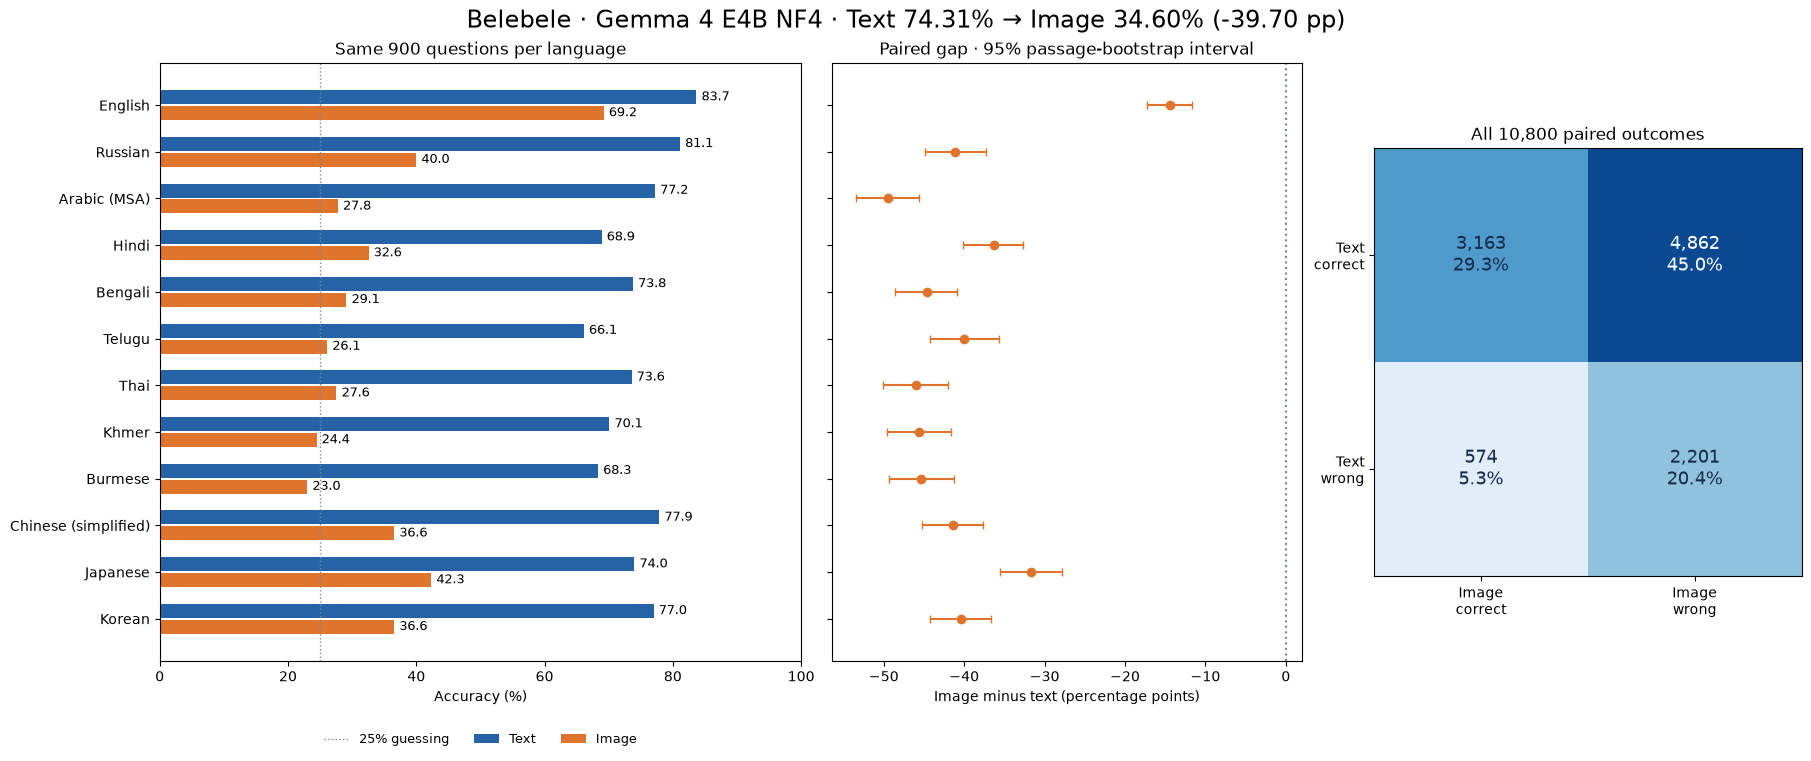

,Language,paired_examples,Text %,Image %,Gap (pp),Gap 95% interval (pp),invalid_responses
0,English,900,83.67,69.22,-14.44,"[-17.24, -11.71]",0
1,Russian,900,81.11,40.00,-41.11,"[-44.83, -37.29]",0
2,Arabic (MSA),900,77.22,27.78,-49.44,"[-53.50, -45.62]",2
3,Hindi,900,68.89,32.56,-36.33,"[-40.13, -32.65]",0
4,Bengali,900,73.78,29.11,-44.67,"[-48.60, -40.84]",0
5,Telugu,900,66.11,26.11,-40.00,"[-44.31, -35.67]",0
6,Thai,900,73.56,27.56,-46.00,"[-50.06, -42.07]",0
7,Khmer,900,70.11,24.44,-45.67,"[-49.61, -41.62]",3
8,Burmese,900,68.33,23.00,-45.33,"[-49.39, -41.24]",44
9,Chinese (simplified),900,77.89,36.56,-41.33,"[-45.19, -37.65]",0


In [2]:
overall = report["groups"][0]
ci = overall["gap_ci95_pp"]
display(Markdown(
    f"**Text: {100 * overall['text_accuracy']:.2f}% · "
    f"Image: {100 * overall['image_accuracy']:.2f}% · "
    f"Gap: {overall['image_minus_text_pp']:.2f} points**  \n"
    f"95% passage-cluster bootstrap interval for the gap: [{ci[0]:.2f}, {ci[1]:.2f}] points."
))
show_plot(plot_overview(report))

language_table = pd.DataFrame(report["groups"][1:])
language_table["Language"] = language_table.language.map(LANGUAGE_NAMES)
language_table["Text %"] = 100 * language_table.text_accuracy
language_table["Image %"] = 100 * language_table.image_accuracy
language_table["Gap (pp)"] = language_table.image_minus_text_pp
language_table["Gap 95% interval (pp)"] = language_table.gap_ci95_pp.map(
    lambda x: f"[{x[0]:.2f}, {x[1]:.2f}]")
display(language_table[["Language", "paired_examples", "Text %", "Image %", "Gap (pp)",
                        "Gap 95% interval (pp)", "invalid_responses"]].style.format(
    {"Text %": "{:.2f}", "Image %": "{:.2f}", "Gap (pp)": "{:.2f}"}))

In [3]:
n = overall["paired_examples"]
outcomes = pd.DataFrame([
    {"Outcome": label, "Pairs": overall[key], "Share %": 100 * overall[key] / n}
    for label, key in [
        ("Both correct", "both_correct"), ("Text correct, image wrong", "text_only_correct"),
        ("Text wrong, image correct", "image_only_correct"), ("Both wrong", "both_wrong")
    ]
])
display(outcomes.style.format({"Share %": "{:.2f}"}))
retained = overall["both_correct"] / (overall["both_correct"] + overall["text_only_correct"])
print(f"Images retain {retained:.2%} of text-correct answers.")

,Outcome,Pairs,Share %
0,Both correct,3163,29.29
1,"Text correct, image wrong",4862,45.02
2,"Text wrong, image correct",574,5.31
3,Both wrong,2201,20.38


Images retain 39.41% of text-correct answers.


## Answer-choice bias and response failures

Compare the answer distributions against the actual gold-label mix, shown above the heatmaps. Concentration on a choice is especially informative when accuracy approaches a constant-answer baseline. The `Invalid` column includes truncated responses, including any truncated single letter.

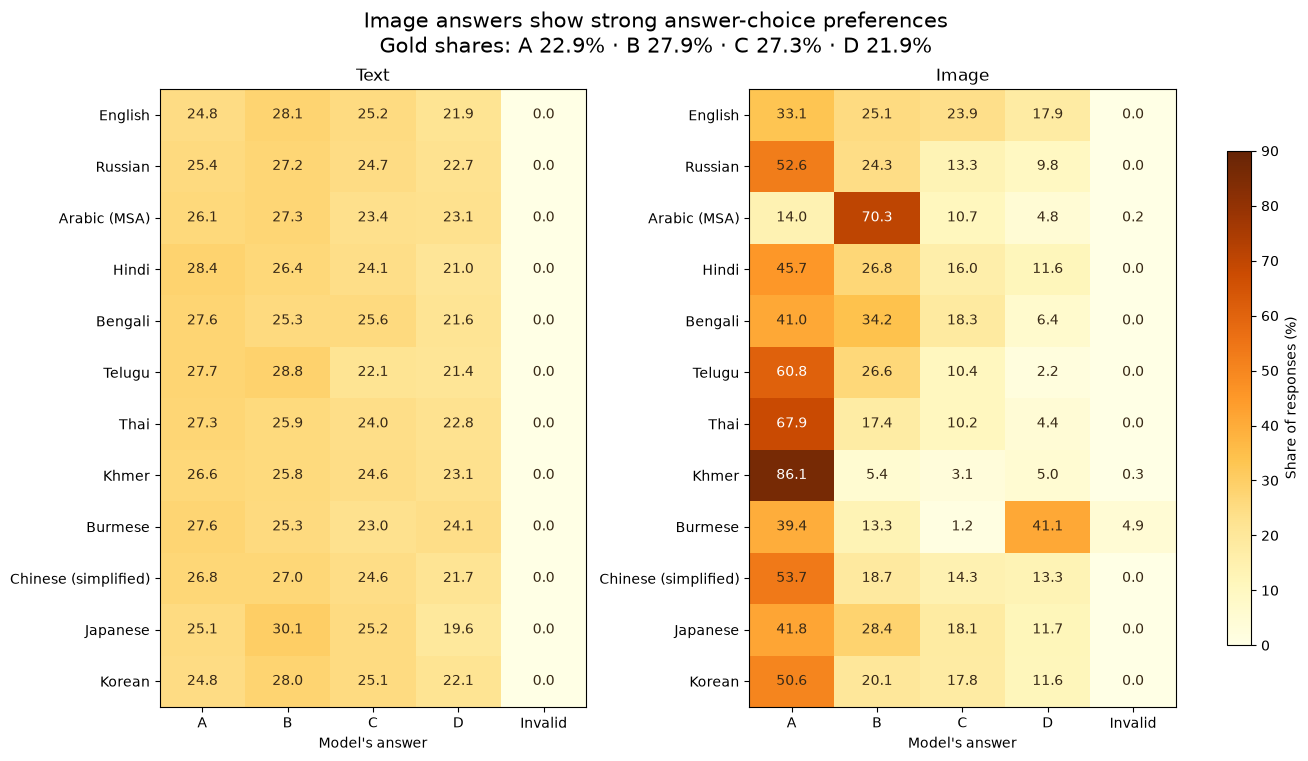

Always choosing the majority gold label: 27.89% accuracy.
Uniform random guessing: 25% expected accuracy.


,Language,mode,n,invalid,truncated
5,Arabic (MSA),image,900,2,2
15,Khmer,image,900,3,3
17,Burmese,image,900,44,44


Invalid and truncated counts overlap; do not add them together.


,language,mode,raw_response,truncated
0,mya_Mymr,image,The user has provided an image containing a pa...,True
1,mya_Mymr,image,The user has provided an image containing a pa...,True
2,mya_Mymr,image,The provided text is in the Burmese language. ...,True
3,mya_Mymr,image,The user has provided a passage in Burmese and...,True
4,mya_Mymr,image,The user has provided an image containing a pa...,True
5,mya_Mymr,image,The user has provided an image containing a pa...,True


In [4]:
show_plot(plot_answer_bias(report))
print(f"Always choosing the majority gold label: {report['majority_answer_baseline_pct']:.2f}% accuracy.")
print("Uniform random guessing: 25% expected accuracy.")
invalid_table = pd.DataFrame(report["invalid_by_language_mode"])
invalid_table["Language"] = invalid_table.language.map(LANGUAGE_NAMES)
display(invalid_table.loc[(invalid_table.invalid > 0) | (invalid_table.truncated > 0),
    ["Language", "mode", "n", "invalid", "truncated"]])
print("Invalid and truncated counts overlap; do not add them together.")
if report["invalid_examples"]:
    display(pd.DataFrame(report["invalid_examples"])[["language", "mode", "raw_response", "truncated"]])

## Processor resizing, page height, and multilingual consistency

The fixed **280-soft-token cap** compresses tall documents more. The first panel shows a geometric proxy: configured 24 px font size × the smaller processor scale. It is **not measured glyph height**. Actual soft-token counts may be below the cap because of patch-grid rounding.

Height quartiles are calculated separately within each language, keeping ties together. Their sizes can differ. These comparisons are descriptive: taller pages can also differ in content and difficulty, so the plot does not isolate a resolution effect. The last panel counts how many translations of each aligned question were answered correctly.

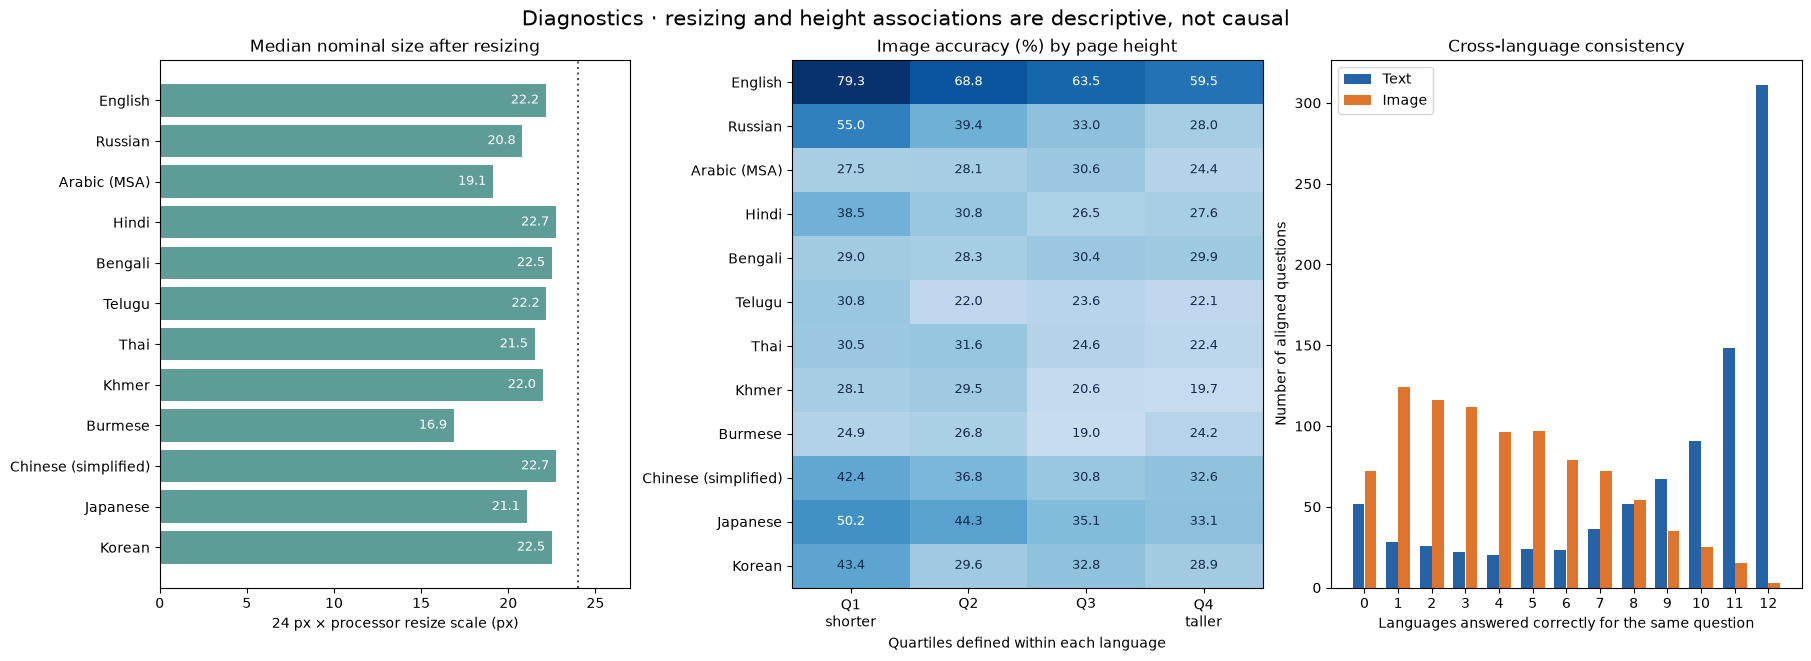

,Language,source_height_min,source_height_median,source_height_max,nominal_font_px_median,soft_tokens_min,soft_tokens_median,soft_tokens_max
0,English,478.0,676.0,1221.0,22.15,255.0,266.0,276.0
1,Russian,478.0,775.0,1518.0,20.81,255.0,266.0,276.0
2,Arabic (MSA),711.0,941.0,1629.0,19.12,255.0,270.0,273.0
3,Hindi,464.0,608.0,1040.0,22.74,252.0,260.0,272.0
4,Bengali,465.0,657.0,1089.0,22.50,252.0,260.0,272.0
5,Telugu,477.0,675.0,1170.0,22.19,255.0,266.0,276.0
6,Thai,529.0,696.0,1195.0,21.52,252.0,266.0,276.0
7,Khmer,478.0,681.5,1325.0,21.98,255.0,266.0,276.0
8,Burmese,817.0,1214.0,2566.0,16.88,250.0,260.0,273.0
9,Chinese (simplified),503.0,608.0,976.0,22.74,252.0,260.0,272.0


height_quartile,Q1 shorter,Q2,Q3,Q4 taller
language,,,,
Arabic (MSA),386,196,183,135
Bengali,238,367,148,147
English,305,176,266,153
Hindi,366,208,181,145
Japanese,233,361,134,172
Khmer,274,176,257,193
Korean,417,206,180,97
Burmese,341,112,315,132
Russian,249,282,176,193


,Language,height_quartile,n,text_accuracy_pct,image_accuracy_pct,gap_pp
0,English,1,305,89.18,79.34,-9.84
3,English,4,153,81.70,59.48,-22.22
4,Russian,1,249,83.13,55.02,-28.11
7,Russian,4,193,79.27,27.98,-51.30
8,Arabic (MSA),1,386,77.98,27.46,-50.52
11,Arabic (MSA),4,135,81.48,24.44,-57.04
12,Hindi,1,366,73.22,38.52,-34.70
15,Hindi,4,145,69.66,27.59,-42.07
16,Bengali,1,238,80.25,28.99,-51.26
19,Bengali,4,147,74.83,29.93,-44.90


In [5]:
show_plot(plot_diagnostics(report))
resize_table = pd.DataFrame(report["resizing"])
resize_table.insert(0, "Language", resize_table.language.map(LANGUAGE_NAMES))
display(resize_table.drop(columns="language").round(2))

# Per-language quartile counts make the height bins auditable.
height_table = pd.DataFrame(report["within_language_height_quartiles"])
display(height_table.pivot(index="language", columns="height_quartile", values="n").rename(
    index=LANGUAGE_NAMES, columns={1: "Q1 shorter", 2: "Q2", 3: "Q3", 4: "Q4 taller"}))
# Compare the shortest/tallest groups in both modalities, so difficulty is visible too.
ends = height_table[height_table.height_quartile.isin([1, 4])].copy()
ends["Language"] = ends.language.map(LANGUAGE_NAMES)
display(ends[["Language", "height_quartile", "n", "text_accuracy_pct", "image_accuracy_pct", "gap_pp"]].round(2))


## Interpretation and the next controlled experiment

- The observed accuracy gap is large in every tested language. English has the strongest image accuracy in this run.
- Image answers show strong option-position preferences, especially Khmer A and Arabic B. Valid wrong answers account for most of the loss; invalid-format failures are a small component.
- Page resizing is a plausible contributor to investigate, but this run cannot separate rendering, preprocessing, visual encoding, reasoning, or quantization effects. It does not establish causal script effects or direct OCR accuracy.
- A useful next comparison would hold IDs, model, prompts, answer order, and rendering fixed while increasing the image budget to 560 or 1120 in a **new run directory**, after checking GPU fit. No such evaluation is launched here.

Uncertainty uses a paired percentile bootstrap over **passage IDs**, carrying all questions, translations, and modalities together. This respects repeated questions within a passage and aligned translations. Intervals describe sensitivity to the sampled passages, not model-seed variation. They are pointwise 95% intervals, not simultaneous bounds; the exact accuracy on this completed corpus is already known.

## Runtime and provenance

Generation latencies exclude loading and preparation and apply to this recorded hardware/software run.

In [6]:
runtime = pd.DataFrame({mode: values for mode, values in report["runtime"].items()
                        if isinstance(values, dict)}).T
runtime["Generation minutes"] = runtime.latency_sum_seconds / 60
display(runtime[["Generation minutes", "latency_median_seconds", "latency_p95_seconds"]].round(3))
print("Model:", report["experiment"]["model_id"])
print("Model revision:", report["experiment"]["model_revision"])
print("Dataset revision:", report["experiment"]["dataset_revision"])
print("Manifest fingerprint:", report["manifest_fingerprint"])
print("Bootstrap:", report["uncertainty"])
# File hashes identify the original input artifacts; this notebook never rewrites them.
display(pd.Series(report["audit"]["original_artifact_sha256"], name="SHA-256").to_frame())

,Generation minutes,latency_median_seconds,latency_p95_seconds
text,32.442,0.174,0.229
image,183.415,1.000,1.129


Model: unsloth/gemma-4-E4B-it-unsloth-bnb-4bit
Model revision: 6f10b2aa522ba471321d8246fd71a3dfa8c5b9a2
Dataset revision: 7899cdfa4e1e0d733fd77c848e2c273cb1d32be2
Manifest fingerprint: f567fe9b4b20b63b648ccfb883b98608a161e02ab1040362070bfd03f505e4a8
Bootstrap: {'method': 'paired percentile passage-cluster bootstrap', 'confidence_level': 0.95, 'repetitions': 5000, 'seed': 42, 'unit': 'passage_id; all questions, translations, and modalities resampled together', 'interpretation': 'Corpus-sampling sensitivity; not repeated inference or model-seed uncertainty.'}


,SHA-256
manifest.json,e018eb20fedb249448e8ee4ae7f9fad036c41ddbd8d043...
selected_ids.json,cc7e76e48dd09e8c276e992f1e5d7941a2810039c6d8d6...
predictions.jsonl,f5c79c60826633dc4ed5860ff86abf60496681c440e198...
metrics.json,b6d9d6aba7ee658b5555e87f2c074e52a5a2ce29090b99...
rendering_metadata.json,7dd746a4f49c2d2dccf1e924ad6c9ac12ecfbb3b990eec...
execution.json,d7d473a71f8aa75abff32c23502fa3fb5877e951cffed5...
sessions.jsonl,ccadb53dd89c2f99e3da162ac4a663d8800401554d7b64...


## Clear plot outputs before saving or sharing

Set `CLEAR_PLOTS = True` and run the next cell to replace the chart displays with text. To clear **all** saved outputs after saving, run:

```bash
.venv/bin/python scripts/clean_notebook.py Belebele_analysis.ipynb
```

Notebook autosave may persist outputs while viewing, so disable it if needed. No chart files or rendered images are created by the analysis. [README](README.md) records model/dataset/renderer attribution and evaluation details.

In [7]:
CLEAR_PLOTS = False  # Set True before saving a clean notebook.
if CLEAR_PLOTS:
    for handle in plot_handles:
        handle.update("Plot cleared; rerun its cell to display it again.")
    plot_handles.clear()
    plt.close("all")
    print("Plot displays cleared.")